# Lending Club Dataset from 2007 to 2018

In [ ]:
!pip install optuna optuna-integration
!pip install category-encoders
!pip install catboost
!pip install cuml-cu12 --extra-index-url=https://pypi.nvidia.com
!pip install xgboost>=2.0 cudf-cu12 --extra-index-url=https://pypi.nvidia.com

In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs
import cupy as cp

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

# Clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder, TargetEncoder
from sklearn.model_selection import RepeatedStratifiedKFold
from category_encoders import CatBoostEncoder, WOEEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from cuml.cluster import KMeans as cuMLKMeans

# GPU models
from cuml.linear_model import LogisticRegression as cuLR
from cuml.ensemble import RandomForestClassifier as cuRF
from cuml.preprocessing import StandardScaler as cuStandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Calibration
from sklearn.calibration import CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression

# Metrics
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    precision_recall_curve
)

# Optuna
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# SHAP
import shap

print('All imports OK')

All imports OK


In [7]:
def csv_to_parquet(path):
    # Read CSV with Polars
    df = pl.read_csv(path, infer_schema_length=10000,
    # null_values=["NA", "n/a", "N/A", ""],
    ignore_errors=True)
    # Save to Parquet on Drive immediately
    parquet_path = path.replace(".csv", ".parquet")
    df.write_parquet(
    parquet_path,
    compression="snappy")

In [ ]:
# Never use CSV again
accepted_df = pl.read_parquet(
    "../data/ml_data/ml_df.parquet"
)
accepted_df.head()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,…,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
i64,str,f64,f64,f64,str,f64,f64,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,f64,f64,str,f64,f64,f64,str,str,str,str,str,f64,f64,f64
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",13.99,123.03,"""C""","""C4""","""leadman""","""10+ years""","""MORTGAGE""",55000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""190xx""","""PA""",5.91,0.0,"""Aug-2003""",675.0,679.0,1.0,30.0,null,7.0,0.0,2765.0,29.7,13.0,…,13734.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",11.99,820.28,"""C""","""C1""","""Engineer""","""10+ years""","""MORTGAGE""",65000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""small_business""","""Business""","""577xx""","""SD""",16.06,1.0,"""Dec-1999""",715.0,719.0,4.0,6.0,null,22.0,0.0,21470.0,19.2,38.0,…,24667.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",10.78,432.66,"""B""","""B4""","""truck driver""","""10+ years""","""MORTGAGE""",63000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""home_improvement""",null,"""605xx""","""IL""",10.78,0.0,"""Aug-2000""",695.0,699.0,0.0,null,null,6.0,0.0,7869.0,56.2,18.0,…,14877.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
66310712,null,35000.0,35000.0,35000.0,""" 60 months""",14.85,829.9,"""C""","""C5""","""Information Systems Officer""","""10+ years""","""MORTGAGE""",110000.0,"""Source Verified""","""Dec-2015""","""Current""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""076xx""","""NJ""",17.06,0.0,"""Sep-2008""",785.0,789.0,0.0,null,null,13.0,0.0,7802.0,11.6,17.0,…,18000.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68476807,null,10400.0,10400.0,10400.0,""" 60 months""",22.45,289.91,"""F""","""F1""","""Contract Specialist""","""3 years""","""MORTGAGE""",104433.0,"""Source

## Defined functions

### WOE Encoder

In [11]:
def generate_oof_encoding(
    X_train, y_train, X_val, X_test,
    cat_cols, encoder_type, cv=None
):
    if cv is None:
        cv = RepeatedStratifiedKFold(
            n_splits=5, n_repeats=5, random_state=42
        )

    X_train_enc = X_train.copy()
    X_val_enc   = X_val.copy()
    X_test_enc  = X_test.copy()

    # ---------------------------------------------------------
    # Stage 1: OOF encoding for train
    # ---------------------------------------------------------
    oof_parts = []

    for train_idx, fold_idx in cv.split(X_train, y_train):
        X_fold_tr  = X_train.iloc[train_idx]
        y_fold_tr  = y_train.iloc[train_idx]
        X_fold_val = X_train.iloc[fold_idx]

        # Fit on this fold's train subset only
        encoder = encoder_type(cols=cat_cols)
        encoder.fit(X_fold_tr[cat_cols], y_fold_tr)

        # Encode the held-out fold slice
        fold_encoded = encoder.transform(X_fold_val[cat_cols])
        # preserve original row index
        fold_encoded.index = X_fold_val.index
        oof_parts.append(fold_encoded)

    # Concatenate all fold slices and sort back to original row order
    oof_encoded = (
        pd.concat(oof_parts)
        .groupby(level=0)
        .mean()
        .reindex(X_train.index)
    )

    # Replace cat columns in train with the OOF-encoded values
    X_train_enc[cat_cols] = oof_encoded[cat_cols].values

    # ---------------------------------------------------------
    # Stage 2: Final encoder on all train → transform val and test
    # ---------------------------------------------------------
    final_encoder = encoder_type(cols=cat_cols)
    final_encoder.fit(X_train[cat_cols], y_train)

    X_val_enc[cat_cols]  = final_encoder.transform(X_val[cat_cols])
    X_test_enc[cat_cols] = final_encoder.transform(X_test[cat_cols])

    return X_train_enc, X_val_enc, X_test_enc

### Isolation Forest

In [12]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler

def outlier_score(
    X_train: np.ndarray,
    X_val:   np.ndarray,
    X_test:  np.ndarray,
    contamination: float = 0.05,
    n_estimators:  int   = 100,
    random_state:  int   = 42
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Trains IsolationForest on X_train only, scores all three splits,
    normalises scores to [-0.5, 0.5].

    IsolationForest.decision_function() has extreme values:
    -0.5 = most anomaly and 0.5 = most normal.

    Parameters
    ----------
    X_train, X_val, X_test : np.ndarray  (float32)
    contamination : expected proportion of outliers in training data
    n_estimators  : number of trees in the forest
    random_state  : reproducibility seed
    col_name      : name tag (used only for the print summary)

    Returns
    -------
    raw_train, raw_val, raw_test : np.ndarray with one column
    """

    print(f"Fitting IsolationForest  (n_estimators={n_estimators}, "
          f"contamination={contamination}) ...")

    iso = IsolationForest(
        n_estimators=n_estimators,
        contamination=contamination,
        random_state=random_state,
        n_jobs=-1
    )
    iso.fit(X_train)

    # decision_function() returns raw score into [-0.5, 0.5] where -0.5 is anomaly and 0.5 is normal
    raw_train = -iso.decision_function(X_train)
    raw_val   = -iso.decision_function(X_val)
    raw_test  = -iso.decision_function(X_test)

    # Summary
    print(f"Train outlier_score — min: {raw_train.min():.4f} - "
          f"max: {raw_train.max():.4f} - "
          f"mean: {raw_train.mean():.4f} - "
          f"flagged (>0.8): {(raw_train > 0.8).sum():,}")
    print(f"Val outlier_score — mean: {raw_val.mean():.4f} - "
          f"flagged (>0.8): {(raw_val > 0.8).sum():,}")
    print(f"Test  outlier_score — mean: {raw_test.mean():.4f} - "
          f"flagged (>0.8): {(raw_test > 0.8).sum():,}")

    return raw_train, raw_val, raw_test

### Split data

In [ ]:
def time_based_split(X: pl.DataFrame, y: pl.Series,
                     split_date: str = "2016-01-01",
                     seed: int = 42):
    assert 'issue_d' in X.columns, 'issue_d column required'

    split_dt = pl.lit(split_date).str.to_date('%Y-%m-%d')

    temp_df = X.with_columns(
    pl.col('issue_d').str.to_date('%b-%Y') if X['issue_d'].dtype == pl.Utf8
    else pl.col('issue_d'),
    target=y
)

    train_pool_df = temp_df.filter(pl.col('issue_d') < split_dt)
    test_df = temp_df.filter(pl.col('issue_d') >= split_dt)

    # Shuffle train pool and take val data same size as text
    val_prop = len(test_df) / len(train_pool_df)
    train_pool_df = train_pool_df.sample(fraction=1.0, shuffle=True, seed=seed)
    # val length == test length
    n_val    = len(test_df)  # val length == test length
    val_df   = train_pool_df.slice(len(train_pool_df) - n_val, n_val)
    train_df = train_pool_df.slice(0, len(train_pool_df) - n_val)

    y_train = train_df['target']
    y_val   = val_df['target']
    y_test  = test_df['target']

    X_train = train_df.drop(['target', 'issue_d', 'earliest_cr_line'])
    X_val   = val_df.drop(['target', 'issue_d', 'earliest_cr_line'])
    X_test  = test_df.drop(['target', 'issue_d', 'earliest_cr_line'])

    print(f"Train: {len(X_train):,} rows")
    print(f"Val: {len(X_val):,} rows  (== Test: {len(X_test):,} rows)")
    print(f"Test: {len(X_test):,} rows")

    return X_train, X_val, X_test, y_train, y_val, y_test


def stratified_kfold_split(model, X: np.ndarray, y: np.ndarray, n_splits=5) -> float:
    """
    Evaluates a model using Stratified K-Fold. Returns mean F1 score.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, valid_idx in skf.split(X, y):
        X_tr, X_va = X[train_idx], X[valid_idx]
        y_tr, y_va = y[train_idx], y[valid_idx]

        # Fit model
        model.fit(X_tr, y_tr)

        # Predict
        preds = model.predict(X_va)
        fold_scores.append(f1_score(y_va, preds))

    return np.mean(fold_scores)

In [ ]:
def to_np(arr):
    """Convert cupy to numpy"""
    return arr.get() if isinstance(arr, cp.ndarray) else np.asarray(arr)

## ML models

### Step 1: Split and Encoding

In [ ]:
X = accepted_df.drop('target')
y = accepted_df['target']

assert len(X) == len(y)
print(f'Encoded X: {X.shape}  |  Default rate: {y.mean()*100:.2f}%')
print(X.schema)

Encoded X: (1277783, 40)  |  Default rate: 20.21%
Schema({'term': Int16, 'int_rate': Float64, 'grade': String, 'sub_grade': Int8, 'purpose': String, 'emp_length': Float64, 'home_ownership': String, 'dti': Float64, 'fico_range_low': Float64, 'earliest_cr_line': Date, 'open_acc': Float64, 'total_acc': Float64, 'mort_acc': Float64, 'tot_cur_bal': Float64, 'revol_bal': Float64, 'revol_util': Float64, 'bc_util': Float64, 'percent_bc_gt_75': Float64, 'inq_last_6mths': Float64, 'issue_d': Date, 'is_ten_plus_years': Int8, 'loan_to_income': Float64, 'inquiries_per_account': Float64, 'active_accounts_ratio': Float64, 'revolbal_to_income': Float64, 'credit_history_years': Float64, 'payment_to_income': Float64, 'revol_stress': Float64, 'total_interest_burden': Float64, 'total_red_flags': Int32, 'annual_inc_arithmetic': Categorical, 'loan_amnt_arithmetic': Categorical, 'annual_inc_quantile': Categorical, 'loan_amnt_quantile': Categorical, 'annual_inc_uniform': String, 'loan_amnt_uniform': String, '

In [15]:
X_train_pl, X_val_pl, X_test_pl, \
y_train_pl, y_val_pl, y_test_pl = time_based_split(X, y, split_date="2016-01-01")

# Convert to Pandas
X_train_pd = X_train_pl.to_pandas()
X_val_pd   = X_val_pl.to_pandas()
X_test_pd  = X_test_pl.to_pandas()
y_train_pd = y_train_pl.to_pandas()
y_val_pd   = y_val_pl.to_pandas()
y_test_pd  = y_test_pl.to_pandas()

Train: 240,371 rows
Val: 518,706 rows  (== Test: 518,706 rows)
Test: 518,706 rows


In [16]:
# Define the categorical columns
cat_cols = [
    'home_ownership', 'grade', 'purpose',
    'annual_inc_arithmetic', 'loan_amnt_arithmetic',
    'annual_inc_quantile', 'loan_amnt_quantile',
    'annual_inc_uniform', 'loan_amnt_uniform'
]

In [17]:
X_train_pd, X_val_pd, X_test_pd = generate_oof_encoding(
    X_train=X_train_pd, y_train=y_train_pd,
    X_val=X_val_pd, X_test=X_test_pd,
    cat_cols=cat_cols, encoder_type=WOEEncoder
)

In [18]:
feature_names = X_train_pd.columns.tolist()

# Numpy
X_train_np = X_train_pd.to_numpy().astype(np.float32)
X_val_np   = X_val_pd.to_numpy().astype(np.float32)
X_test_np  = X_test_pd.to_numpy().astype(np.float32)
y_train_np = y_train_pl.to_numpy().astype(np.float32)
y_val_np   = y_val_pl.to_numpy().astype(np.float32)
y_test_np  = y_test_pl.to_numpy().astype(np.float32)

# GPU arrays for cuML
X_train_gpu = cp.asarray(X_train_pd.to_numpy(), dtype=cp.float32)
X_val_gpu   = cp.asarray(X_val_pd.to_numpy(),   dtype=cp.float32)
X_test_gpu  = cp.asarray(X_test_pd.to_numpy(),  dtype=cp.float32)
y_train_gpu = cp.asarray(y_train_np)
y_val_gpu   = cp.asarray(y_val_np)
y_test_gpu  = cp.asarray(y_test_np)

# Imbalance ratio — computed from train only
neg, pos = (y_train_np == 0).sum(), (y_train_np == 1).sum()
imbalance_ratio = neg / pos
print(f"Imbalance ratio (neg/pos): {imbalance_ratio:.2f}")
print(f"Feature count: {len(feature_names)}")

Imbalance ratio (neg/pos): 4.35
Feature count: 38


### Step 2: Isolation Forest Signal

In [19]:
raw_outlier_train, raw_outlier_val, raw_outlier_test = outlier_score(
    X_train_np, X_val_np, X_test_np,
    contamination=0.05,   # assume ~5% of training rows are anomalous
    n_estimators=100,
    random_state=42
)

Fitting IsolationForest  (n_estimators=100, contamination=0.05) ...
Train outlier_score — min: -0.1433 - max: 0.1375 - mean: -0.0592 - flagged (>0.8): 0
Val outlier_score — mean: -0.0598 - flagged (>0.8): 0
Test  outlier_score — mean: -0.0528 - flagged (>0.8): 0


### Step 3: Optuna Hyperparameter Tuning

In [20]:
def to_np(arr):
    """Convert cupy to numpy"""
    return arr.get() if isinstance(arr, cp.ndarray) else np.asarray(arr)

In [23]:
N_FOLDS = 4
SKF = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

# Logistic Regression
def objective_lr(trial):
    C = trial.suggest_float('C', 1e-3, 10.0, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)

    fold_scores = []
    for fold_idx, (tr_idx, va_idx) in enumerate(SKF.split(X_train_np, y_train_np)):
        X_tr = cp.asarray(X_train_np[tr_idx])
        X_va = cp.asarray(X_train_np[va_idx])
        y_tr = cp.asarray(y_train_np[tr_idx])
        y_va = y_train_np[va_idx]

        scaler = cuStandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_va = scaler.transform(X_va)

        model = cuLR(
            C=C, penalty='elasticnet', l1_ratio=l1_ratio,
            max_iter=1000, class_weight='balanced'
        )
        model.fit(X_tr, y_tr)

        proba = to_np(model.predict_proba(X_va))[:, 1]
        # score the probability outputs and do not set threshold
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_scores))


# Random Forest (cuML GPU)
def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1000),
        'max_depth':    trial.suggest_int('max_depth', 2, 10),
        'max_samples':  trial.suggest_float('max_samples', 0.5, 0.9),
        'max_features': trial.suggest_float('max_features', 0.5, 0.9),
        'random_state': 42,
    }

    fold_scores = []
    for fold_idx, (tr_idx, va_idx) in enumerate(SKF.split(X_train_np, y_train_np)):
        X_tr, X_va = X_train_np[tr_idx], X_train_np[va_idx]
        y_tr, y_va = y_train_np[tr_idx], y_train_np[va_idx]

        rf = cuRF(**params)
        rf.fit(X_tr, y_tr)

        proba = to_np(rf.predict_proba(X_va))[:, 1]
        # score the probability outputs and do not set threshold
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    avg = float(np.mean(fold_scores))

    # Store final model (retrained on full train) for later
    rf_full = cuRF(**params)
    rf_full.fit(X_train_np, y_train_np)
    trial.set_user_attr('model', rf_full)

    return avg


# XGBoost (GPU)
def objective_xgb(trial):
    params = {
        'n_estimators':    trial.suggest_int('n_estimators', 300, 1000),
        'max_depth':       trial.suggest_int('max_depth', 2, 10),
        'learning_rate':   trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'subsample':       trial.suggest_float('subsample', 0.5, 0.9),
        'colsample_bytree':trial.suggest_float('colsample_bytree', 0.5, 0.9),
        'reg_alpha':       trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),   # L1
        'reg_lambda':      trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),  # L2
        'scale_pos_weight':trial.suggest_float('scale_pos_weight', 1.0, 10.0),
        'objective':       'binary:logistic',
        'eval_metric':     'aucpr',
        'tree_method':     'hist',
        'device':          'cuda',
        'random_state':    42,
        'verbosity':       0,
    }

    fold_scores = []
    for fold_idx, (tr_idx, va_idx) in enumerate(SKF.split(X_train_np, y_train_np)):
        X_tr, X_va = X_train_np[tr_idx], X_train_np[va_idx]
        y_tr, y_va = y_train_np[tr_idx], y_train_np[va_idx]

        model = XGBClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

        proba = model.predict_proba(X_va)[:, 1]
        # score the probability outputs and do not set threshold
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    avg = float(np.mean(fold_scores))

    # Store model retrained on full train set
    xgb_full = XGBClassifier(**params)
    xgb_full.fit(X_train_np, y_train_np, verbose=False)
    trial.set_user_attr('model', xgb_full)

    return avg


# CatBoost (GPU) has no L1 regularization due to symmetry
def objective_cb(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 300, 1000),
        'depth': trial.suggest_int('depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 0.9),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'scale_pos_weight':trial.suggest_float('scale_pos_weight', 1.0, 10.0),
        'objective': 'Logloss',
        'grow_policy': 'SymmetricTree',
        'task_type': 'GPU',
        'eval_metric': 'Logloss',
        'random_state': 42,
        'verbose': 0,
        'bootstrap_type': 'Poisson', # Added to enable subsample
    }

    fold_scores = []
    for fold_idx, (tr_idx, va_idx) in enumerate(SKF.split(X_train_np, y_train_np)):
        X_tr, X_va = X_train_np[tr_idx], X_train_np[va_idx]
        y_tr, y_va = y_train_np[tr_idx], y_train_np[va_idx]

        model = CatBoostClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

        proba = model.predict_proba(X_va)[:, 1]
        # score the probability outputs and do not set threshold
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    avg = float(np.mean(fold_scores))

    # Store model retrained on full train set
    xgb_full = CatBoostClassifier(**params)
    xgb_full.fit(X_train_np, y_train_np, verbose=False)
    trial.set_user_attr('model', xgb_full)

    return avg


# LightGBM (GPU)
def objective_lgbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1000),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),   # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),  # L2
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 10.0),
        'objective': 'binary',
        'metric': 'average_precision',
        'boosting_type': 'gbdt',
        'device': 'gpu',
        'random_state': 42,
        'verbose': -1,
    }

    fold_scores = []
    for fold_idx, (tr_idx, va_idx) in enumerate(SKF.split(X_train_np, y_train_np)):
        X_tr, X_va = X_train_np[tr_idx], X_train_np[va_idx]
        y_tr, y_va = y_train_np[tr_idx], y_train_np[va_idx]

        model = LGBMClassifier(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
                  callbacks=[lgbm_log_callback()])

        proba = model.predict_proba(X_va)[:, 1]
        # score the probability outputs and do not set threshold
        score = average_precision_score(y_va, proba)
        fold_scores.append(score)

        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned()

    avg = float(np.mean(fold_scores))

    lgbm_full = LGBMClassifier(**params)
    lgbm_full.fit(X_train_np, y_train_np,
                  callbacks=[lgbm_log_callback()])
    trial.set_user_attr('model', lgbm_full)

    return avg


def lgbm_log_callback():
    """Suppress LightGBM training logs."""
    import lightgbm as lgb
    return lgb.log_evaluation(period=-1)

In [24]:
# Run Optuna Studies
N_TRIALS = 60
studies = {}

for name, objective_fn in [
    ('LogisticRegression', objective_lr),
    ('RandomForest', objective_rf),
    ('XGBoost', objective_xgb),
    ('CatBoost', objective_cb),
    ('LightGBM', objective_lgbm),
]:
    print(f'\n{"*"*60}')
    print(f'Tuning {name} …')
    print(f'{"*"*60}')

    # compare value of a trial against the median of previous trials
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(n_startup_trials=20, seed=42),
        pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=2),
        study_name=f'{name}_f1',
    )

    study.optimize(objective_fn, n_trials=N_TRIALS, show_progress_bar=True)
    studies[name] = study
    pruned = sum(1 for t in study.trials if t.state == optuna.trial.TrialState.PRUNED)

    print(f'Best F1: {study.best_value:.4f}')
    print(f'Pruned: {pruned}/{N_TRIALS}')
    print(f'Best params: {study.best_params}')

[I 2026-06-08 10:25:27,967] A new study created in memory with name: LogisticRegression_f1



************************************************************
Tuning LogisticRegression …
************************************************************


  0%|          | 0/60 [00:00<?, ?it/s]

[2026-06-08 10:25:28.179] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[2026-06-08 10:25:28.622] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[I 2026-06-08 10:25:28,860] Trial 0 finished with value: 0.3691096490511049 and parameters: {'C': 0.03148911647956861, 'l1_ratio': 0.9507143064099162}. Best is trial 0 with value: 0.3691096490511049.
[2026-06-08 10:25:29.302] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[2026-06-08 10:25:29.527] [CUML] [warning] QWL-QN line search failed (code 3); stopping at the last valid step
[I 2026-06-08 10:25:29,767] Trial 1 finished with value: 0.36935989355482823 and parameters: {'C': 0.8471801418819978, 'l1_ratio': 0.5986584841970366}. Best is trial 1 with value: 0.36935989355482823.
[2026-06-08 10:25:30.397] [CUML] [warning] QWL-QN stopped, because the line search failed to advance (step delta = 0.000000)
[2026-06-08 10:25:30.608] [CUM

[I 2026-06-08 10:26:22,005] A new study created in memory with name: RandomForest_f1


[I 2026-06-08 10:26:21,998] Trial 59 finished with value: 0.36945913251787865 and parameters: {'C': 3.171923005597164, 'l1_ratio': 0.8791698511583028}. Best is trial 51 with value: 0.36947031684524484.
Best F1: 0.3695
Pruned: 1/60
Best params: {'C': 3.530072138945998, 'l1_ratio': 0.8129507022081153}

************************************************************
Tuning RandomForest …
************************************************************


... (10 outputs left out)

[I 2026-06-08 11:07:23,840] A new study created in memory with name: LightGBM_f1


[I 2026-06-08 11:07:23,705] Trial 59 finished with value: 0.37722401980950965 and parameters: {'iterations': 749, 'depth': 4, 'learning_rate': 0.05123170191885423, 'subsample': 0.7540508950116699, 'l2_leaf_reg': 0.01755942093811818, 'scale_pos_weight': 1.7029214330175617}. Best is trial 52 with value: 0.37770133364034536.
Best F1: 0.3777
Pruned: 5/60
Best params: {'iterations': 755, 'depth': 5, 'learning_rate': 0.06028285402625537, 'subsample': 0.7423223143034161, 'l2_leaf_reg': 0.07179818261458887, 'scale_pos_weight': 2.3175771617809895}

************************************************************
Tuning LightGBM …
************************************************************


  0%|          | 0/60 [00:00<?, ?it/s]

[I 2026-06-08 11:07:56,821] Trial 0 finished with value: 0.37510451980431125 and parameters: {'n_estimators': 562, 'max_depth': 10, 'learning_rate': 0.029106359131330698, 'subsample': 0.7394633936788146, 'colsample_bytree': 0.7468055921327309, 'reg_alpha': 0.004207053950287938, 'reg_lambda': 0.0017073967431528124, 'scale_pos_weight': 8.795585311974417}. Best is trial 0 with value: 0.37510451980431125.
[I 2026-06-08 11:08:40,743] Trial 1 finished with value: 0.3625666502954733 and parameters: {'n_estimators': 721, 'max_depth': 8, 'learning_rate': 0.0010994335574766201, 'subsample': 0.8879639408647977, 'colsample_bytree': 0.9497327922401265, 'reg_alpha': 0.0070689749506246055, 'reg_lambda': 0.005337032762603957, 'scale_pos_weight': 2.650640588680904}. Best is trial 0 with value: 0.37510451980431125.
[I 2026-06-08 11:09:09,968] Trial 2 finished with value: 0.37107371115098137 and parameters: {'n_estimators': 513, 'max_depth': 6, 'learning_rate': 0.007309539835912915, 'subsample': 0.616491

### Step 4: Rebuild Best Models & Calibrate on Training Data

In [25]:
# --- Logistic Regression ---
best_lr_params = studies['LogisticRegression'].best_params
scaler_final = cuStandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_gpu)

best_lr = cuLR(
    C=best_lr_params['C'],
    penalty='elasticnet',
    l1_ratio=best_lr_params['l1_ratio'],
    max_iter=1000,
    class_weight='balanced',
    tol=1e-3,
    linesearch_max_iter=50
)
best_lr.fit(X_train_scaled, y_train_gpu)

# --- Random Forest ---
best_rf = studies['RandomForest'].best_trial.user_attrs['model']
best_rf_params = studies['RandomForest'].best_params

# --- XGBoost (from stored model) ---
best_xgb = studies['XGBoost'].best_trial.user_attrs['model']
best_xgb_params = studies['XGBoost'].best_params

# --- CatBoost (from stored model) ---
best_cb = studies['CatBoost'].best_trial.user_attrs['model']
best_cb_params = studies['CatBoost'].best_params

# --- LightGBM (from stored model) ---
best_lgbm = studies['LightGBM'].best_trial.user_attrs['model']
best_lgbm_params = studies['LightGBM'].best_params

print('Best models rebuilt / retrieved.')
for name, params in [
    ('LR', best_lr_params),
    ('RF', best_rf_params),
    ('XGB', best_xgb_params),
    ('CatBoost', best_cb_params),
    ('LGBM', best_lgbm_params),
]:
    print(f'{name}: {params}')

Best models rebuilt / retrieved.
LR: {'C': 3.530072138945998, 'l1_ratio': 0.8129507022081153}
RF: {'n_estimators': 595, 'max_depth': 10, 'max_samples': 0.5027417679222994, 'max_features': 0.6243701496180075}
XGB: {'n_estimators': 695, 'max_depth': 5, 'learning_rate': 0.027657600430756824, 'subsample': 0.7744312219678898, 'colsample_bytree': 0.8330433978041126, 'reg_alpha': 3.564193855915267, 'reg_lambda': 1.249570387021615, 'scale_pos_weight': 1.9210634906054285}
CatBoost: {'iterations': 755, 'depth': 5, 'learning_rate': 0.06028285402625537, 'subsample': 0.7423223143034161, 'l2_leaf_reg': 0.07179818261458887, 'scale_pos_weight': 2.3175771617809895}
LGBM: {'n_estimators': 884, 'max_depth': 2, 'learning_rate': 0.09984577548106965, 'subsample': 0.7781458397907549, 'colsample_bytree': 0.8418144888311303, 'reg_alpha': 0.2586857648761709, 'reg_lambda': 0.005118271093239208, 'scale_pos_weight': 7.366452292909215}


In [26]:
calibrators = {}

# LR (cuML → IsotonicRegression)
X_val_scaled  = scaler_final.transform(X_val_gpu)
lr_val_proba  = to_np(best_lr.predict_proba(X_val_scaled))[:, 1]
iso_lr        = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip')
iso_lr.fit(lr_val_proba, y_val_np)
calibrators['LogisticRegression'] = iso_lr
print('LR calibrated on val.')

# RF (cuML → IsotonicRegression)
rf_val_proba  = to_np(best_rf.predict_proba(X_val_np))[:, 1]
iso_rf        = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip')
iso_rf.fit(rf_val_proba, y_val_np)
calibrators['RandomForest'] = iso_rf
print('RF calibrated on val.')

# XGBoost (CalibratedClassifierCV, cv='prefit')
# cv='prefit": ML already fitted
cal_xgb = CalibratedClassifierCV(best_xgb, method='isotonic', cv='prefit')
cal_xgb.fit(X_val_np, y_val_np)
calibrators['XGBoost'] = cal_xgb
print('XGBoost calibrated on val.')

# CatBoost (CalibratedClassifierCV, cv='prefit')
cal_cb = CalibratedClassifierCV(best_cb, method='isotonic', cv='prefit')
cal_cb.fit(X_val_np, y_val_np)
calibrators['CatBoost'] = cal_cb
print('CatBoost calibrated on val.')

# LightGBM (CalibratedClassifierCV, cv='prefit')
cal_lgbm = CalibratedClassifierCV(best_lgbm, method='isotonic', cv='prefit')
cal_lgbm.fit(X_val_np, y_val_np)
calibrators['LightGBM'] = cal_lgbm
print('LightGBM calibrated on val.')

print('\nAll calibrations complete.')

LR calibrated on val.
RF calibrated on val.
XGBoost calibrated on val.
CatBoost calibrated on val.
LightGBM calibrated on val.

All calibrations complete.


### Step 5: Evaluate Best Models & Calibrated Models on Validation/Test

In [27]:
# --- Calibrated output probabilities ---
def get_calibrated_proba(name, raw_proba, X_np=None):
    """Apply the validation calibrator depending on model type."""
    cal = calibrators[name]
    if isinstance(cal, CalibratedClassifierCV):
        # CalibratedClassifierCV wraps the base model
        return cal.predict_proba(X_np)[:, 1]
    else:
        # IsotonicRegression transforms the 1D proba array
        return cal.transform(raw_proba)

def eval_metrics(y_true, y_proba, raw_outlier, label='', alpha=0.5, beta=0.5):
    """Print key metrics and return a dict."""
    y_pred = np.where((raw_outlier > alpha) |
                      (y_proba > beta), 1, 0)
    pr_auc = average_precision_score(y_true, y_proba)
    roc    = roc_auc_score(y_true, y_proba)
    f1     = f1_score(y_true, y_pred, zero_division=0)
    prec   = precision_score(y_true, y_pred, zero_division=0)
    rec    = recall_score(y_true, y_pred, zero_division=0)
    return {'label': label, 'pr_auc': pr_auc, 'roc_auc': roc,
            'f1': f1, 'precision': prec, 'recall': rec,
            'best_alpha': alpha, 'best_beta': beta}


def evaluate_split(split_name, X_np, X_gpu, raw_outlier, y_np, alpha=None, beta=None):
    results = []
    print(f'\nUncalibrated models on {split_name}')

    # ---------------------------------------------------------
    # Uncalibrated
    # ---------------------------------------------------------
    X_scaled    = scaler_final.transform(X_gpu)
    lr_proba    = to_np(best_lr.predict_proba(X_scaled))[:, 1]
    rf_proba    = to_np(best_rf.predict_proba(X_np))[:, 1]
    xgb_proba   = best_xgb.predict_proba(X_np)[:, 1]
    cb_proba    = best_cb.predict_proba(X_np)[:, 1]
    lgbm_proba  = best_lgbm.predict_proba(X_np)[:, 1]

    for proba, label in [
        (lr_proba,   'LR (uncalibrated)'),
        (rf_proba,   'RF (uncalibrated)'),
        (xgb_proba,  'XGB (uncalibrated)'),
        (cb_proba,   'CB (uncalibrated)'),
        (lgbm_proba, 'LGBM (uncalibrated)'),
    ]:

        # Find best alpha and beta for each model. Then use in test df
        if split_name == 'val':
            # --- Unified validation df ---
            val_df = pd.DataFrame({
                'ml_probability': proba,
                'anomaly_score':  raw_outlier,
                'true_target':    y_np
            })

            # --- Objective ---
            def objective_hybrid_thresholds(trial):
                alpha = trial.suggest_float('alpha', -0.5, 0.5)
                beta  = trial.suggest_float('beta',  0.0, 1.0)

                y_pred = np.where(
                    (val_df['anomaly_score']  > alpha) |
                    (val_df['ml_probability'] > beta),
                    1, 0
                )
                return f1_score(val_df['true_target'], y_pred, zero_division=0)

            # --- Optuna tuning ---
            study = optuna.create_study(
                    direction='maximize',
                    sampler=optuna.samplers.TPESampler(seed=42)
            )
            study.optimize(objective_hybrid_thresholds, n_trials=500, show_progress_bar=True)
            best_alpha = study.best_params['alpha']
            best_beta  = study.best_params['beta']
            alpha = pd.Series([best_alpha], index=[label]) # Store as Series
            beta  = pd.Series([best_beta], index=[label])  # Store as Series
        else:
            best_alpha = alpha.loc[label]
            best_beta  = beta.loc[label]

        results.append(eval_metrics(y_np, proba, raw_outlier, label, best_alpha, best_beta))

    # ---------------------------------------------------------
    # Calibrated
    # ---------------------------------------------------------
    print(f'\nCalibrated models on {split_name}')

    # cuML models — IsotonicRegression.transform(raw_proba)
    lr_cal   = calibrators['LogisticRegression'].transform(lr_proba)
    rf_cal   = calibrators['RandomForest'].transform(rf_proba)

    # sklearn models — CalibratedClassifierCV.predict_proba(X)
    xgb_cal  = calibrators['XGBoost'].predict_proba(X_np)[:, 1]
    cb_cal   = calibrators['CatBoost'].predict_proba(X_np)[:, 1]
    lgbm_cal = calibrators['LightGBM'].predict_proba(X_np)[:, 1]

    for proba, label in [
        (lr_cal,   'LR (calibrated)'),
        (rf_cal,   'RF (calibrated)'),
        (xgb_cal,  'XGB (calibrated)'),
        (cb_cal,   'CB (calibrated)'),
        (lgbm_cal, 'LGBM (calibrated)'),
    ]:
        if split_name == 'val':
            # --- Unified validation df ---
            val_df = pd.DataFrame({
                'ml_probability': proba,
                'anomaly_score':  raw_outlier,
                'true_target':    y_np
            })

            # --- Objective ---
            def objective_hybrid_thresholds(trial):
                alpha = trial.suggest_float('alpha', -0.5, 0.5)
                beta  = trial.suggest_float('beta',  0.0, 1.0)

                y_pred = np.where(
                    (val_df['anomaly_score']  > alpha) |
                    (val_df['ml_probability'] > beta),
                    1, 0
                )
                return f1_score(val_df['true_target'], y_pred, zero_division=0)

            # --- Optuna tuning ---
            study = optuna.create_study(
                    direction='maximize',
                    sampler=optuna.samplers.TPESampler(seed=42)
            )
            study.optimize(objective_hybrid_thresholds, n_trials=500, show_progress_bar=True)
            best_alpha = study.best_params['alpha']
            best_beta  = study.best_params['beta']
            alpha = pd.Series([best_alpha], index=[label]) # Store as Series
            beta  = pd.Series([best_beta], index=[label])  # Store as Series
        else:
            best_alpha = alpha.loc[label]
            best_beta  = beta.loc[label]

        results.append(eval_metrics(y_np, proba, raw_outlier, label, best_alpha, best_beta))

    return pd.DataFrame(results).set_index('label')

In [28]:
val_df  = evaluate_split('val', X_val_np, X_val_gpu, raw_outlier_val, y_val_np)
test_df = evaluate_split('test', X_test_np, X_test_gpu, raw_outlier_test, y_test_np, alpha=val_df['best_alpha'], beta=val_df['best_beta'])

print('\n── Val Summary ──')
print(val_df.to_string())

print('\n── Test Summary ──')
print(test_df.to_string())


Uncalibrated models on val


[I 2026-06-08 11:34:34,314] A new study created in memory with name: no-name-ee7c7a6c-da2d-4e7c-8bf4-ed923a72f29a


  0%|          | 0/500 [00:00<?, ?it/s]

[I 2026-06-08 11:34:34,362] Trial 0 finished with value: 0.3152944164171888 and parameters: {'alpha': -0.1254598811526375, 'beta': 0.9507143064099162}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:34:34,402] Trial 1 finished with value: 0.4137888844706818 and parameters: {'alpha': 0.2319939418114051, 'beta': 0.5986584841970366}. Best is trial 1 with value: 0.4137888844706818.
[I 2026-06-08 11:34:34,438] Trial 2 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.3439813595575635, 'beta': 0.15599452033620265}. Best is trial 1 with value: 0.4137888844706818.
[I 2026-06-08 11:34:34,475] Trial 3 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.44191638783180054, 'beta': 0.8661761457749352}. Best is trial 1 with value: 0.4137888844706818.
[I 2026-06-08 11:34:34,512] Trial 4 finished with value: 0.3254192045744493 and parameters: {'alpha': 0.1011150117432088, 'beta': 0.7080725777960455}. Best is trial 1 with value: 0.4137888844706818

[I 2026-06-08 11:34:57,909] A new study created in memory with name: no-name-836b33e6-550c-4a60-a5d7-154ea6f50aa0


  0%|          | 0/500 [00:00<?, ?it/s]

... (21 outputs left out)

[I 2026-06-08 11:37:48,524] Trial 0 finished with value: 0.3152944164171888 and parameters: {'alpha': -0.1254598811526375, 'beta': 0.9507143064099162}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:37:48,562] Trial 1 finished with value: 0.03411599438089504 and parameters: {'alpha': 0.2319939418114051, 'beta': 0.5986584841970366}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:37:48,598] Trial 2 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.3439813595575635, 'beta': 0.15599452033620265}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:37:48,645] Trial 3 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.44191638783180054, 'beta': 0.8661761457749352}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:37:48,689] Trial 4 finished with value: 0.0013177265099807488 and parameters: {'alpha': 0.1011150117432088, 'beta': 0.7080725777960455}. Best is trial 0 with value: 0.315294416417

[I 2026-06-08 11:38:12,393] A new study created in memory with name: no-name-57454bb6-5f15-4f55-938c-3c28603434bb


  0%|          | 0/500 [00:00<?, ?it/s]

[I 2026-06-08 11:38:12,438] Trial 0 finished with value: 0.3152944164171888 and parameters: {'alpha': -0.1254598811526375, 'beta': 0.9507143064099162}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:38:12,476] Trial 1 finished with value: 0.04106911339383664 and parameters: {'alpha': 0.2319939418114051, 'beta': 0.5986584841970366}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:38:12,512] Trial 2 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.3439813595575635, 'beta': 0.15599452033620265}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:38:12,548] Trial 3 finished with value: 0.31517848442524443 and parameters: {'alpha': -0.44191638783180054, 'beta': 0.8661761457749352}. Best is trial 0 with value: 0.3152944164171888.
[I 2026-06-08 11:38:12,585] Trial 4 finished with value: 0.0013587515955037674 and parameters: {'alpha': 0.1011150117432088, 'beta': 0.7080725777960455}. Best is trial 0 with value: 0.315294416417

### Step 6: Global Feature Importance

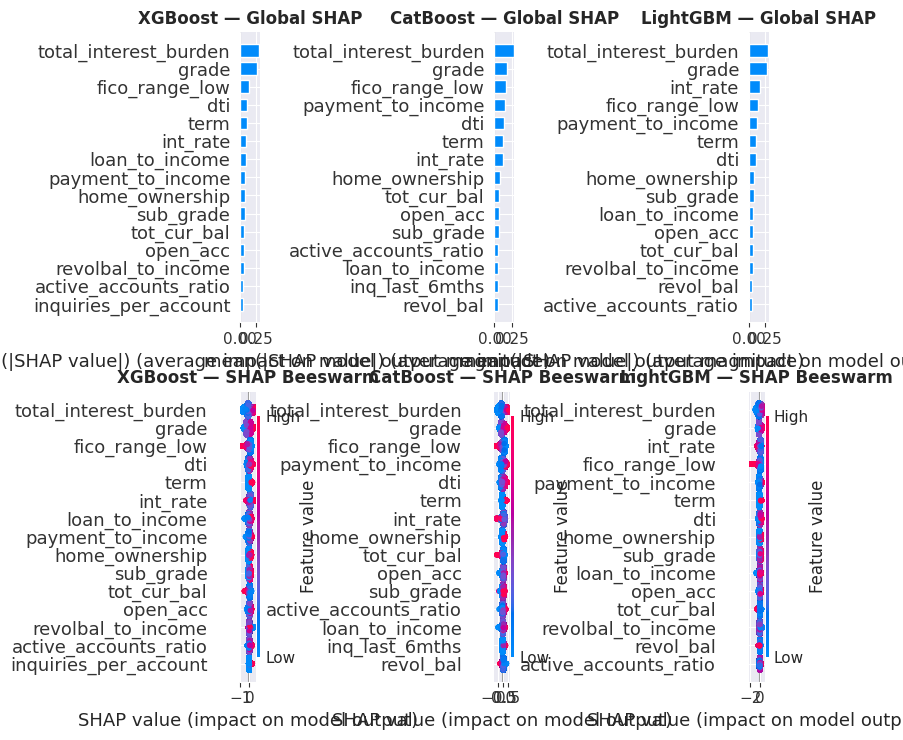

In [29]:
# 1. FIXED: Wider figure size
fig, axes = plt.subplots(2, 3, figsize=(24, 12))

shap_models = {
    'XGBoost':  best_xgb,
    'CatBoost': best_cb,
    'LightGBM': best_lgbm,
}

# TreeExplainer for tree models (Bar plots)
for idx, (name, model) in enumerate(shap_models.items()):
    ax = axes[idx // 3, idx % 3]
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_pd)
    plt.sca(ax)
    shap.summary_plot(shap_values, X_test_pd, feature_names=feature_names,
                      plot_type='bar', show=False, max_display=15)
    ax.set_title(f'{name} — Global SHAP', fontweight='bold')

# Beeswarm for XGBoost
ax = axes[1, 0]
explainer_xgb = shap.TreeExplainer(best_xgb)
shap_vals_xgb = explainer_xgb.shap_values(X_test_pd)
plt.sca(ax)
shap.summary_plot(shap_vals_xgb, X_test_pd, feature_names=feature_names,
                  show=False, max_display=15)
ax.set_title('XGBoost — SHAP Beeswarm', fontweight='bold')

# Beeswarm for CatBoost
ax = axes[1, 1]
explainer_cb = shap.TreeExplainer(best_cb)
shap_vals_cb = explainer_cb.shap_values(X_test_pd)
plt.sca(ax)
shap.summary_plot(shap_vals_cb, X_test_pd, feature_names=feature_names,
                  show=False, max_display=15)
ax.set_title('CatBoost — SHAP Beeswarm', fontweight='bold')

# Beeswarm for LightGBM
ax = axes[1, 2]
explainer_lgbm = shap.TreeExplainer(best_lgbm)
shap_vals_lgbm = explainer_lgbm.shap_values(X_test_pd)
plt.sca(ax)
shap.summary_plot(shap_vals_lgbm, X_test_pd, feature_names=feature_names,
                  show=False, max_display=15)
ax.set_title('LightGBM — SHAP Beeswarm', fontweight='bold')

# 2. FIXED: Added padding to prevent overlap
plt.tight_layout(w_pad=5.0, h_pad=3.0)
plt.savefig('shap_global_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## Unified Evaluation - Final Comparison
**What to do:**

- Collect metrics from all 4 methods (Tasks 3, 4, 5 + baseline ✅) into one results table
- Build profit-risk tradeoff chart: plot cumulative profit vs NPL ratio for all 4 methods on one figure
- Write the Results & Discussion section of the paper:
    - Does the Constrained DQN outperform the bandit baseline on NPL compliance?
    - Does the penalty (Method 2 vs 3) make a meaningful difference?
    - Does the RL approach outperform the static classifier policy in profit?
    - What do the findings mean for a real bank's compliance team?

**Input needed:** Metrics from Tasks 3, 4, 5 - ⚠️ must wait for all three

**Deliverables:**

- Unified results table (all 4 methods, all metrics)
- Profit-risk tradeoff plot
- Written Results & Discussion section (draft)

**Deadline:** `[TBD - last task, after all others]`

Train 3 models + evaluate on test set

In [30]:
def get_preds(proba, raw_outlier, label, df):
    alpha = df.loc[label, 'best_alpha']
    beta  = df.loc[label, 'best_beta']
    return np.where((raw_outlier > alpha) | (proba > beta), 1, 0)

# Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_test_scaled  = scaler.transform(X_test_np)
lr = cuLR(max_iter=1000, C=1.0)
lr.fit(X_train_scaled, y_train_np)
lr_proba = cp.asnumpy(lr.predict_proba(X_test_scaled)[:, 1])
lr_preds = get_preds(lr_proba, raw_outlier_test, 'LR (calibrated)', val_df)

# Random Forest
rf = cuRF(**best_rf_params, random_state=42)
rf.fit(X_train_np, y_train_np)
rf_proba = to_np(rf.predict_proba(X_test_gpu))[:, 1]
rf_preds = get_preds(rf_proba, raw_outlier_test, 'RF (calibrated)', val_df)

# XGBoost
xgb = XGBClassifier(
    **best_xgb_params,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    device="cuda",
    random_state=42
)
xgb.fit(X_train_np, y_train_np)
xgb_proba = xgb.predict_proba(X_test_np)[:, 1]
xgb_preds = get_preds(xgb_proba, raw_outlier_test, 'XGB (calibrated)', val_df)

# CatBoost
cb = CatBoostClassifier(
    **best_cb_params, bootstrap_type='Poisson',
    objective='Logloss', eval_metric='Logloss',
    task_type='GPU', random_state=42, verbose=0)
cb.fit(X_train_np, y_train_np)
cb_proba = cb.predict_proba(X_test_np)[:, 1]
cb_preds = get_preds(cb_proba, raw_outlier_test, 'CB (calibrated)', val_df)

# LightGBM
lgbm = LGBMClassifier(
    **best_lgbm_params,
    objective='binary',
    eval_metric='average_precision',
    boosting_type='gbdt',
    device="gpu",
    random_state=42
)
lgbm.fit(X_train_np, y_train_np)
lgbm_proba = lgbm.predict_proba(X_test_np)[:, 1]
lgbm_preds = get_preds(lgbm_proba, raw_outlier_test, 'LGBM (calibrated)', val_df)

print("\n")
for name, preds, proba in [
    ("Logistic Regression", lr_preds,  lr_proba),
    ("Random Forest",       rf_preds,  rf_proba),
    ("XGBoost",             xgb_preds, xgb_proba),
    ("CatBoost",            cb_preds,  cb_proba),
    ("LightGBM",            lgbm_preds, lgbm_proba),  # was missing from your loop
]:
    print(f"\n{'─'*20} {name} {'─'*20}")
    print(f"Precision: {precision_score(y_test_pd, preds, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_test_pd, preds):.3f}")
    print(f"F1:        {f1_score(y_test_pd, preds):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test_pd, proba):.3f}")
    print(f"PR-AUC:    {average_precision_score(y_test_pd, proba):.3f}")
    print(classification_report(y_test_pd, preds))




──────────────────── Logistic Regression ────────────────────
Precision: 0.374
Recall:    0.527
F1:        0.437
ROC-AUC:   0.703
PR-AUC:    0.386
              precision    recall  f1-score   support

           0       0.85      0.74      0.79    402449
           1       0.37      0.53      0.44    116257

    accuracy                           0.70    518706
   macro avg       0.61      0.64      0.61    518706
weighted avg       0.74      0.70      0.71    518706


──────────────────── Random Forest ────────────────────
Precision: 0.379
Recall:    0.509
F1:        0.435
ROC-AUC:   0.705
PR-AUC:    0.399
              precision    recall  f1-score   support

           0       0.84      0.76      0.80    402449
           1       0.38      0.51      0.43    116257

    accuracy                           0.70    518706
   macro avg       0.61      0.63      0.62    518706
weighted avg       0.74      0.70      0.72    518706


──────────────────── XGBoost ────────────────────
Pre

Static Lending Policy + benchmark table

In [31]:
#################
class LendingEnv:
    RATE_TIERS = {1: 0.08, 2: 0.13, 3: 0.19}

    def __init__(self, df, feature_cols, target_col="target"):
        self.df   = df.reset_index(drop=True)
        self.cols = feature_cols
        self.target_col = target_col
        self.idx  = 0

    def reset(self):
        self.idx = 0
        return self._obs()

    def _obs(self):
        row = self.df.iloc[self.idx]
        return row[self.cols].values.astype(float), row

    def step(self, action):
        _, row    = self._obs()
        defaulted = int(row[self.target_col])
        loan_amnt = float(row["loan_amnt_trunc"])

        if action == 0:
            reward = 0.0
        elif defaulted:
            reward = -loan_amnt
        else:
            reward = self.RATE_TIERS[action] * loan_amnt

        self.idx   += 1
        done        = self.idx >= len(self.df)
        next_obs    = None if done else self._obs()
        return next_obs, reward, done, {"default": defaulted, "action": action}

#################
def static_lending_policy(model,
                          X_train: np.ndarray,
                          X_test: np.ndarray,
                          y_train: np.ndarray,
                          y_test: np.ndarray,
                          feature_cols: list):
    cv_precision = stratified_kfold_split(model, X_train, y_train)
    print(f"Precision score of {model}: {cv_precision:.3f}")

    test_df_env = pd.DataFrame(X_test, columns=feature_cols)
    test_df_env["target"] = y_test
    # get probabilities from the xgb model trained above
    model_probs = model.predict_proba(X_test)[:, 1] # convert to numpy

    # initialize evironment
    env = LendingEnv(test_df_env, feature_cols=feature_cols, target_col='target')
    obs_tuple = env.reset()

    total_profit, n_approved, n_defaults = 0.0, 0, 0

    print("--- Running Static ML Policy Simulation ---")
    for i in range(len(test_df_env)):
        feats, row = obs_tuple
        prob = model_probs[i]

        # Static Policy Logic based on probability thresholds
        if prob < 0.05:
            action = 1  # Low risk, low rate tier
        elif prob < 0.1:
            action = 2  # Medium risk, medium rate tier
        elif prob < 0.2:
            action = 3  # High risk, high rate tier
        else:
            action = 0  # Reject

        next_obs, reward, done, info = env.step(action)
        total_profit += reward

        if action != 0:
            n_approved += 1
            if info["default"]:
                n_defaults += 1

        if i % 50_000 == 0:
            npl = n_defaults / max(n_approved, 1)
            print(f"Step={i:,} | profit=${total_profit:,.0f} | NPL={npl:.2%}")

        if done:
            break
        obs_tuple = next_obs

    # Output results
    model_name = type(model).__name__
    approval_rate = n_approved / len(test_df_env)
    npl = n_defaults / max(n_approved, 1)
    avg_profit_loan = total_profit/max(n_approved, 1)

    print(f"\n[Static ML Policy] FINAL RESULTS")
    print(f"  Total profit   : ${total_profit:,.0f}")
    print(f"  Approved loans : {n_approved:,} / {len(test_df_env):,}")
    print(f"  Approval rate  : {n_approved / len(test_df_env):.2%}")
    print(f"  NPL ratio      : {npl:.2%}")
    print(f"  Avg profit/loan: ${total_profit / max(n_approved, 1):,.2f}")

    return model_name, total_profit, n_approved, approval_rate, npl, avg_profit_loan

In [32]:
feature_cols = [f"f{i}" for i in range(X_train_pd.shape[1])]  # replace with your actual column names

results = []
for name, model in [("Logistic Regression", lr),
                    ("Random Forest", rf),
                    ("XGBoost", xgb),
                    ("CatBoost", cb)]:
    print(f"\n{'*'*55}\nRunning static policy: {name}\n{'*'*55}")
    # Pass CuPy arrays for training data to stratified_kfold_split within static_lending_policy
    # The static_lending_policy function handles the conversion back to numpy for model.predict_proba
    # and uses the pandas DataFrames for the LendingEnv.
    r = static_lending_policy(model, X_train_np, X_test_np,
                              y_train_np, y_test_np, feature_cols=X_test_pd.columns)
    results.append(r)

# Benchmark table
bench = pd.DataFrame(results, columns=["model", "total_profit", "n_approved", "approval_rate", "npl_ratio", "avg_profit"]).set_index("model")
bench["total_profit"]  = bench["total_profit"].map("${:,.0f}".format)
bench["approval_rate"] = bench["approval_rate"].map(lambda x: f"{x:.2%}")
bench["npl_ratio"]     = bench["npl_ratio"].map(lambda x: f"{x:.2%}")
bench["avg_profit"]    = bench["avg_profit"].map("${:,.0f}".format)
print(f"\n{'*'*55}\nBenchmark\n{'*'*55}")
print(bench.to_string())


*******************************************************
Running static policy: Logistic Regression
*******************************************************
[2026-06-08 11:48:42.557] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
[2026-06-08 11:48:42.853] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
[2026-06-08 11:48:42.923] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
[2026-06-08 11:48:42.987] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
[2026-06-08 11:48:43.049] [CUML] [warning] L-BFGS line search failed (code 4); stopping at the last valid step
Precision score of LogisticRegression(): 0.000
--- Running Static ML Policy Simulation ---
Step=0 | profit=$325 | NPL=0.00%
Step=50,000 | profit=$-55,056,250 | NPL=18.31%
Step=100,000 | profit=$-123,407,525 | NPL=19.87%
Step=150,000 | profit=$-175,466,650 | NPL=19.45%
Step=200,000 | profi

SHAP importance on XGBoost

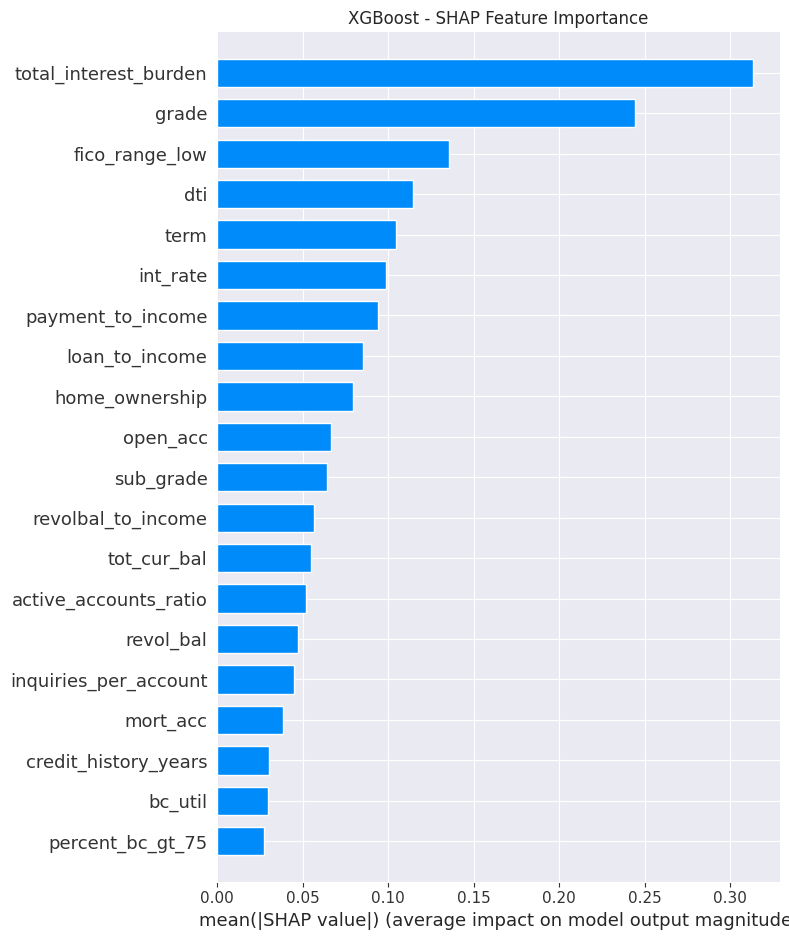

In [33]:
explainer  = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_pd)

plt.figure()
shap.summary_plot(shap_values, X_test_pd,
                  feature_names=X_test_pd.columns,
                  plot_type="bar",
                  show=False)
plt.title("XGBoost - SHAP Feature Importance")
plt.tight_layout()
plt.show()

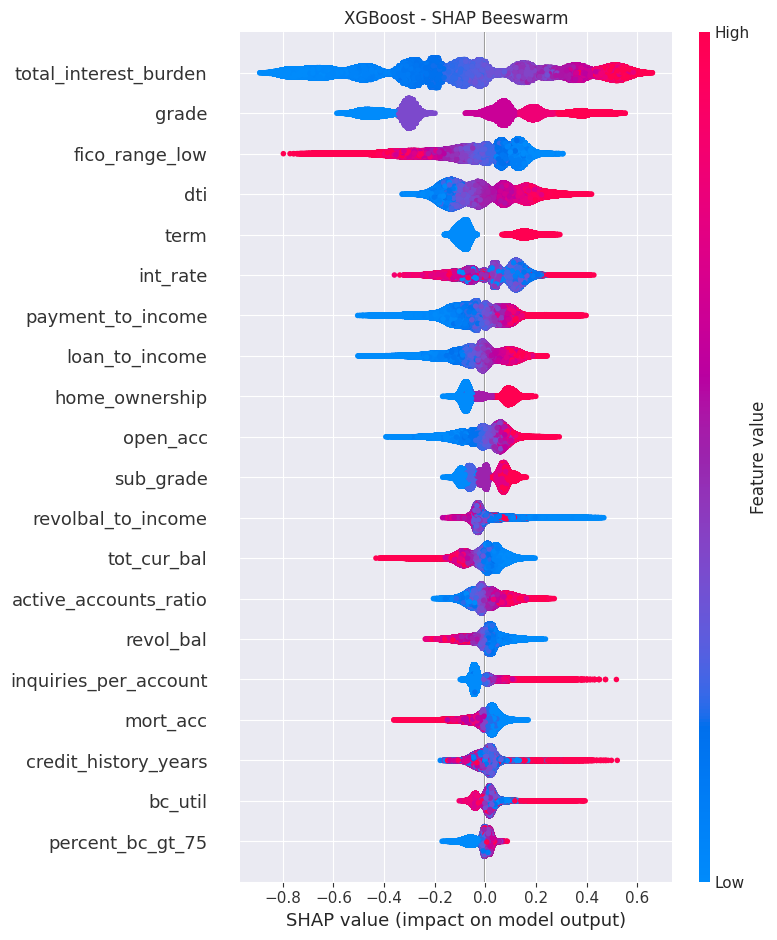

In [34]:
shap.summary_plot(shap_values, X_test_pd,
                  feature_names=X_test_pd.columns,
                  show=False)
plt.title("XGBoost - SHAP Beeswarm")
plt.tight_layout()
plt.show()